# Final project : *Income Analysis and model deployment*


## Detil
### nama dataset adult.csv dan adult.test.csv
### Exploratory Data Analysis (EDA) dan data pre-processing terhadap dataset di  atas. Latih sebuah model machine learning berdasarkan data dan persoalan tersebut lalu di deploy dengan streamlit
### Menggunakan Google Colab.

# Income Analysis and modelling also deoployment

**In this kernel I will create a machine learning model on the Census Income dataset. The objective of this project is to build a model to predict whether personal income would be over 50 or not based on pattern extracted from analysing features.**




# Step 1 Importing Relevant  libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import os

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
#machine learning libraries:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.model_selection import cross_val_score, cross_val_predict

#evaluation
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import r2_score,f1_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve

import warnings
warnings.filterwarnings('ignore')

# Step 2 Import Dataset dari google drive

In [ ]:
!pip -q install gdown

import gdown
import os
import pandas as pd

# Google Drive File IDs
file_id_train = "1gw9JcfQERMQKUe2gAOHK-QXq7_D8yaZD"
file_id_test = "1htovoft-4ODgFcxCYYLCivec41-G93DM"

# Lokasi penyimpanan di Colab
train_data = "/content/adult.csv"
test_data = "/content/adult.test.csv"

# Download files
gdown.download(id=file_id_train, output=train_data, quiet=False)
gdown.download(id=file_id_test, output=test_data, quiet=False)

# Tampilkan file di folder Session
print("\n=== FILE DI FOLDER SESSION ===")
for filename in os.listdir("/content"):
    if filename in ["adult.csv", "adult.test.csv"]:
        path = os.path.join("/content", filename)
        print(f"{filename} | {os.path.getsize(path):,} bytes")

Downloading...
From: https://drive.google.com/uc?id=1gw9JcfQERMQKUe2gAOHK-QXq7_D8yaZD
To: /content/adult.csv
100%|██████████| 3.84M/3.84M [00:00<00:00, 30.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1htovoft-4ODgFcxCYYLCivec41-G93DM
To: /content/adult.test.csv
100%|██████████| 1.94M/1.94M [00:00<00:00, 18.0MB/s]


=== FILE DI FOLDER SESSION ===
adult.test.csv | 1,938,007 bytes
adult.csv | 3,844,225 bytes


In [ ]:
# Membaca CSV menjadi DataFrame
train_data = pd.read_csv("/content/adult.csv")
test_data = pd.read_csv("/content/adult.test.csv")



## cek bentuk file nya

In [ ]:
# Menampilkan data
train_data.head()

,Age,Workclass,Final Weight,Education,EducationNum,Marital Status,Occupation,Relationship,Race,Gender,Capital Gain,capital loss,Hours per Week,Native Country,Income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Cek dataset secara global

In [ ]:
# Ukuran dataset (baris, kolom)
print("Ukuran dataset train_data:", train_data.shape)
print("Ukuran dataset test_data:", test_data.shape)
# Total baris dan kolom
total_baris = train_data.shape[0] + test_data.shape[0]
total_kolom = train_data.shape[1]

# Persentase training dan testing
persen_train = (train_data.shape[0] / total_baris) * 100
persen_test = (test_data.shape[0] / total_baris) * 100

print("\n=== RINGKASAN DATASET ===")
print("Total baris kedua dataset:", total_baris)
print("Total kolom:", total_kolom)
print("Total ukuran dataset gabungan:", (total_baris, total_kolom))

print("\n=== PROPORSI DATASET ===")
print(f"Data Training : {train_data.shape[0]:,} baris ({persen_train:.2f}%)")
print(f"Data Testing  : {test_data.shape[0]:,} baris ({persen_test:.2f}%)")
print(f"Total         : {total_baris:,} baris ({persen_train + persen_test:.2f}%)")


Ukuran dataset train_data: (32561, 15)
Ukuran dataset test_data: (16280, 15)

=== RINGKASAN DATASET ===
Total baris kedua dataset: 48841
Total kolom: 15
Total ukuran dataset gabungan: (48841, 15)

=== PROPORSI DATASET ===
Data Training : 32,561 baris (66.67%)
Data Testing  : 16,280 baris (33.33%)
Total         : 48,841 baris (100.00%)


In [ ]:
# Nama kolom
print("\nNama kolom:")
print(train_data.columns.tolist())
print(test_data.columns.tolist())


Nama kolom:
['Age', 'Workclass', 'Final Weight', 'Education', 'EducationNum', 'Marital Status', 'Occupation', 'Relationship', 'Race', 'Gender', 'Capital Gain', 'capital loss', 'Hours per Week', 'Native Country', 'Income']
['25', ' Private', '226802', ' 11th', '7', ' Never-married', ' Machine-op-inspct', ' Own-child', ' Black', ' Male', '0', '0.1', '40', ' United-States', ' <=50K.']


In [ ]:
# Informasi tipe data dan missing values
print("\nInformasi dataset:")
train_data.info()


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Age             32561 non-null  int64 
 1   Workclass       32561 non-null  object
 2   Final Weight    32561 non-null  int64 
 3   Education       32561 non-null  object
 4   EducationNum    32561 non-null  int64 
 5   Marital Status  32561 non-null  object
 6   Occupation      32561 non-null  object
 7   Relationship    32561 non-null  object
 8   Race            32561 non-null  object
 9   Gender          32561 non-null  object
 10  Capital Gain    32561 non-null  int64 
 11  capital loss    32561 non-null  int64 
 12  Hours per Week  32561 non-null  int64 
 13  Native Country  32561 non-null  object
 14  Income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
# Jumlah missing values per kolom
print("\nMissing values:")
print(train_data.isnull().sum())


Missing values:
Age               0
Workclass         0
Final Weight      0
Education         0
EducationNum      0
Marital Status    0
Occupation        0
Relationship      0
Race              0
Gender            0
Capital Gain      0
capital loss      0
Hours per Week    0
Native Country    0
Income            0
dtype: int64


In [ ]:

# Statistik deskriptif
from IPython.display import display, HTML

# Judul besar dan tebal
display(HTML("<h2><b>Statistik Deskriptif</b></h2>"))

print(train_data.describe(include="all"))

                 Age Workclass  Final Weight Education  EducationNum  \
count   32561.000000     32561  3.256100e+04     32561  32561.000000   
unique           NaN         9           NaN        16           NaN   
top              NaN   Private           NaN   HS-grad           NaN   
freq             NaN     22696           NaN     10501           NaN   
mean       38.581647       NaN  1.897784e+05       NaN     10.080679   
std        13.640433       NaN  1.055500e+05       NaN      2.572720   
min        17.000000       NaN  1.228500e+04       NaN      1.000000   
25%        28.000000       NaN  1.178270e+05       NaN      9.000000   
50%        37.000000       NaN  1.783560e+05       NaN     10.000000   
75%        48.000000       NaN  2.370510e+05       NaN     12.000000   
max        90.000000       NaN  1.484705e+06       NaN     16.000000   

             Marital Status       Occupation Relationship    Race Gender  \
count                 32561            32561        32561  

# Step 3: Evaluate Data Structure

In [ ]:
# Step 3: Evaluate data structure
train_data.head()
# **krn ini klasifikasai "Income" nanti kita tidak pakai**

,Age,Workclass,Final Weight,Education,EducationNum,Marital Status,Occupation,Relationship,Race,Gender,Capital Gain,capital loss,Hours per Week,Native Country,Income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# Step 4: Check Target Variable Distribution

Before modelling, we examine the distribution of the target variable (`Income`) across the two classes: `<=50K` and `>50K`.

**Why?** If one class substantially outnumbers the other, accuracy alone can be misleading. A model that mostly predicts the majority class may achieve high accuracy while failing to identify individuals in the minority class.

**Evaluation metrics:** We evaluate **Accuracy, Precision, Recall, F1 Score, F2 Score, and ROC AUC** to assess model performance from different perspectives.

**F2 Score** places greater emphasis on recall than precision. Here, it helps assess the model’s ability to identify individuals earning `>50K`. This emphasis does not assume that false negatives are more costly, since the project has not established specific error costs.

**Handling class imbalance:** We compare models trained before and after SMOTE. SMOTE is applied only to the training data, while the original testing data remains unchanged for all experiments.

Value counts:
Income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Proportions:
Income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64


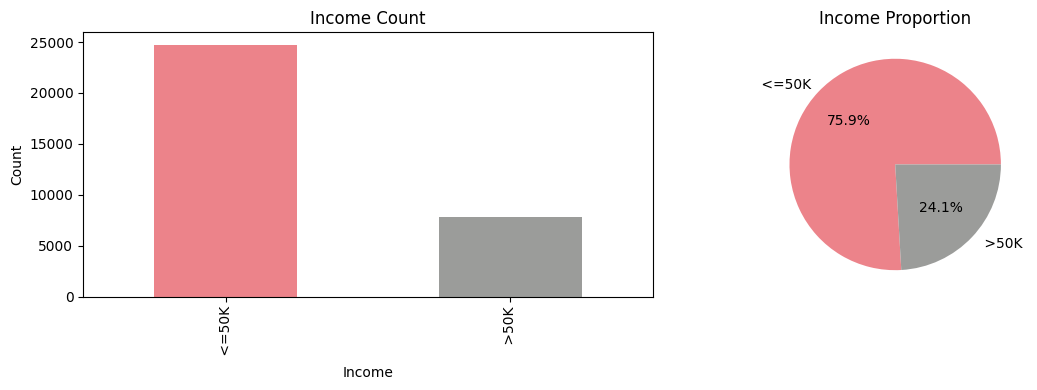

KESIMPULAN : Class Income *imbalance*


In [ ]:
# Step 4: Check Target Variable Distribution
print("Value counts:")
print(train_data["Income"].value_counts())
print()
print("Proportions:")
print(train_data["Income"].value_counts(normalize=True).round(4) * 100)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_data["Income"].value_counts().plot(kind='bar', ax=axes[0], color=['#ec838a', '#9b9c9a'])
axes[0].set_title("Income Count")
axes[0].set_ylabel("Count")
train_data["Income"].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%',
                                      colors=['#ec838a', '#9b9c9a'])
axes[1].set_title("Income Proportion")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()
print("KESIMPULAN : Class Income *imbalance*")

# Step 5: Clean the Dataset

**Data checks:** Examine both training and testing datasets for incorrect data types, missing values, extra spaces, duplicate rows, and numerical outliers.

**Missing values:** Standardize missing-value markers such as `?` and blank strings. Fill missing categorical values with `"Unknown"`. If numerical values are missing, fill them using medians calculated from the training data.

**Duplicates and outliers:** Retain identical rows because the dataset has no unique respondent identifier. Check numerical values against reasonable ranges and retain valid outliers.

**Consistent processing:** Apply the same cleaning rules to both datasets. Any values learned during preprocessing, such as numerical medians, must come from the training data only.

## import kedua dataset adut.csv dan adult.test.csv

In [ ]:
# Import dataset training
train_data = pd.read_csv("adult.csv", skipinitialspace=True)

# Import dataset testing tanpa header
test_data = pd.read_csv(
    "adult.test.csv",
    header=None,
    names=train_data.columns,
    skipinitialspace=True
)

# Menghilangkan tanda titik pada label Income di testing
test_data["Income"] = test_data["Income"].str.rstrip(".")

# Periksa hasil
print("Training:", train_data.shape)
print("Testing :", test_data.shape)

display(test_data.head())

Training: (32561, 15)
Testing : (16281, 15)


,Age,Workclass,Final Weight,Education,EducationNum,Marital Status,Occupation,Relationship,Race,Gender,Capital Gain,capital loss,Hours per Week,Native Country,Income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


##  1.Memeriksa tipe data tiap variabel

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Membuat salinan agar dataset asli tidak berubah
train_clean = train_data.copy()
test_clean = test_data.copy()

def judul(teks):
    display(HTML(f"<h2><b>{teks}</b></h2>"))

judul("1. Pemeriksaan Tipe Data")

for nama, df in [("Training", train_clean), ("Testing", test_clean)]:
    print(f"\nDataset {nama}: {df.shape}")
    display(pd.DataFrame({
        "Variabel": df.columns,
        "Tipe Data": df.dtypes.astype(str).values,
        "Non-Null": df.notna().sum().values,
        "Jumlah Unik": df.nunique().values
    }))

# Pastikan struktur kedua dataset sama
assert train_clean.columns.equals(test_clean.columns), (
    "Nama atau urutan kolom training dan testing berbeda."
)


Dataset Training: (32561, 15)


,Variabel,Tipe Data,Non-Null,Jumlah Unik
0,Age,int64,32561,73
1,Workclass,object,32561,9
2,Final Weight,int64,32561,21648
3,Education,object,32561,16
4,EducationNum,int64,32561,16
5,Marital Status,object,32561,7
6,Occupation,object,32561,15
7,Relationship,object,32561,6
8,Race,object,32561,5
9,Gender,object,32561,2



Dataset Testing: (16281, 15)


,Variabel,Tipe Data,Non-Null,Jumlah Unik
0,Age,int64,16281,73
1,Workclass,object,16281,9
2,Final Weight,int64,16281,12787
3,Education,object,16281,16
4,EducationNum,int64,16281,16
5,Marital Status,object,16281,7
6,Occupation,object,16281,15
7,Relationship,object,16281,6
8,Race,object,16281,5
9,Gender,object,16281,2


##  2.Handle Missing Data (missing values, space, and ?)

In [ ]:
judul("2. Pemeriksaan Missing Values, Spasi, dan Tanda ?")

def cek_kebersihan(df):
    hasil = []

    for col in df.columns:
        s = df[col]

        if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
            teks = s.astype("string")
            spasi = teks.ne(teks.str.strip()).fillna(False).sum()
            tanda_tanya = teks.str.strip().eq("?").fillna(False).sum()
            kosong = teks.str.strip().eq("").fillna(False).sum()
        else:
            spasi = tanda_tanya = kosong = 0

        hasil.append({
            "Variabel": col,
            "Missing Values": s.isna().sum(),
            "Spasi Tambahan": spasi,
            "Tanda ?": tanda_tanya,
            "String Kosong": kosong
        })

    return pd.DataFrame(hasil)

print("SEBELUM CLEANING - TRAINING")
display(cek_kebersihan(train_clean))

print("SEBELUM CLEANING - TESTING")
display(cek_kebersihan(test_clean))

# Membersihkan kedua dataset
for df in [train_clean, test_clean]:
    cat_cols = df.select_dtypes(include=["object", "string"]).columns

    for col in cat_cols:
        df[col] = df[col].astype("string").str.strip()

    df.replace(["?", ""], np.nan, inplace=True)

# Normalisasi label Income pada dataset testing
for df in [train_clean, test_clean]:
    df["Income"] = df["Income"].str.rstrip(".")

print("\nSETELAH CLEANING - TRAINING")
display(cek_kebersihan(train_clean))

print("SETELAH CLEANING - TESTING")
display(cek_kebersihan(test_clean))

SEBELUM CLEANING - TRAINING


,Variabel,Missing Values,Spasi Tambahan,Tanda ?,String Kosong
0,Age,0,0,0,0
1,Workclass,0,0,1836,0
2,Final Weight,0,0,0,0
3,Education,0,0,0,0
4,EducationNum,0,0,0,0
5,Marital Status,0,0,0,0
6,Occupation,0,0,1843,0
7,Relationship,0,0,0,0
8,Race,0,0,0,0
9,Gender,0,0,0,0


SEBELUM CLEANING - TESTING


,Variabel,Missing Values,Spasi Tambahan,Tanda ?,String Kosong
0,Age,0,0,0,0
1,Workclass,0,0,963,0
2,Final Weight,0,0,0,0
3,Education,0,0,0,0
4,EducationNum,0,0,0,0
5,Marital Status,0,0,0,0
6,Occupation,0,0,966,0
7,Relationship,0,0,0,0
8,Race,0,0,0,0
9,Gender,0,0,0,0



SETELAH CLEANING - TRAINING


,Variabel,Missing Values,Spasi Tambahan,Tanda ?,String Kosong
0,Age,0,0,0,0
1,Workclass,1836,0,0,0
2,Final Weight,0,0,0,0
3,Education,0,0,0,0
4,EducationNum,0,0,0,0
5,Marital Status,0,0,0,0
6,Occupation,1843,0,0,0
7,Relationship,0,0,0,0
8,Race,0,0,0,0
9,Gender,0,0,0,0


SETELAH CLEANING - TESTING


,Variabel,Missing Values,Spasi Tambahan,Tanda ?,String Kosong
0,Age,0,0,0,0
1,Workclass,963,0,0,0
2,Final Weight,0,0,0,0
3,Education,0,0,0,0
4,EducationNum,0,0,0,0
5,Marital Status,0,0,0,0
6,Occupation,966,0,0,0
7,Relationship,0,0,0,0
8,Race,0,0,0,0
9,Gender,0,0,0,0


##  3.Handle duplicated data

In [ ]:
judul("3. Pemeriksaan Duplikasi")

for nama, df in [("Training", train_clean), ("Testing", test_clean)]:
    jumlah = df.duplicated().sum()

    print(f"\nDataset {nama}")
    print("Jumlah duplikat:", jumlah)
    print("Persentase:", round(jumlah / len(df) * 100, 2), "%")

    if jumlah > 0:
        print("Contoh data duplikat:")
        display(df[df.duplicated(keep=False)].head(10))


Dataset Training
Jumlah duplikat: 24
Persentase: 0.07 %
Contoh data duplikat:


,Age,Workclass,Final Weight,Education,EducationNum,Marital Status,Occupation,Relationship,Race,Gender,Capital Gain,capital loss,Hours per Week,Native Country,Income
2303,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
3917,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
4325,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
4767,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,<=50K
4881,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
4940,38,Private,207202,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,48,United-States,>50K
5104,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
5579,27,Private,255582,HS-grad,9,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40,United-States,<=50K
5805,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
5842,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala,<=50K



Dataset Testing
Jumlah duplikat: 5
Persentase: 0.03 %
Contoh data duplikat:


,Age,Workclass,Final Weight,Education,EducationNum,Marital Status,Occupation,Relationship,Race,Gender,Capital Gain,capital loss,Hours per Week,Native Country,Income
488,24,Private,194630,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,35,United-States,<=50K
864,24,Private,194630,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,35,United-States,<=50K
1319,37,Private,52870,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,<=50K
3900,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
7021,30,Private,180317,Assoc-voc,11,Divorced,Machine-op-inspct,Not-in-family,White,Male,0,0,40,United-States,<=50K
9249,29,Private,36440,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Female,0,0,40,United-States,<=50K
11189,37,Private,52870,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,<=50K
11212,29,Private,36440,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Female,0,0,40,United-States,<=50K
13848,30,Private,180317,Assoc-voc,11,Divorced,Machine-op-inspct,Not-in-family,White,Male,0,0,40,United-States,<=50K
15960,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K


## 4.Handle outlier on  numerical variable

OUTLIER DATA TRAINING


,Variabel,Minimum,Maximum,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,Age,17,90,-2.0,78.0,143,0.44
1,Final Weight,12285,1484705,-61009.0,415887.0,992,3.05
2,EducationNum,1,16,4.5,16.5,1198,3.68
3,Capital Gain,0,99999,0.0,0.0,2712,8.33
4,capital loss,0,4356,0.0,0.0,1519,4.67
5,Hours per Week,1,99,32.5,52.5,9008,27.66


OUTLIER DATA TESTING


,Variabel,Minimum,Maximum,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,Age,17,90,-2.0,78.0,73,0.45
1,Final Weight,13492,1490400,-65736.0,420856.0,471,2.89
2,EducationNum,1,16,4.5,16.5,596,3.66
3,Capital Gain,0,99999,0.0,0.0,1323,8.13
4,capital loss,0,3770,0.0,0.0,763,4.69
5,Hours per Week,1,99,32.5,52.5,4488,27.57


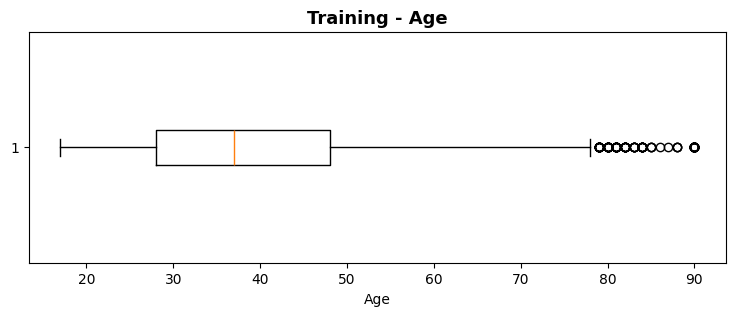

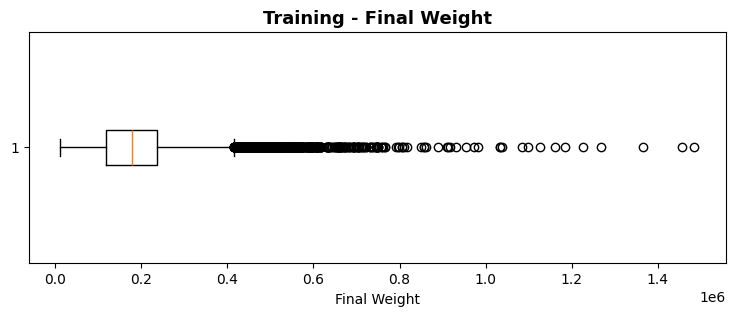

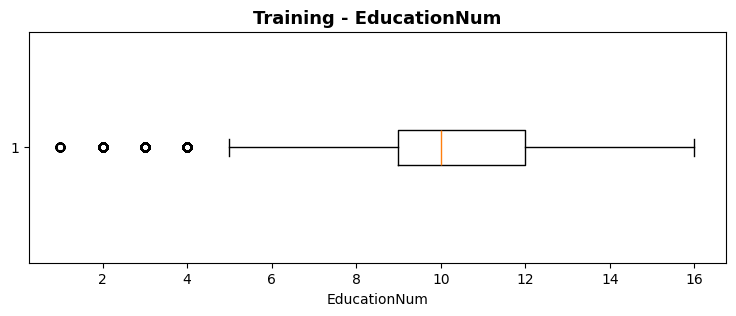

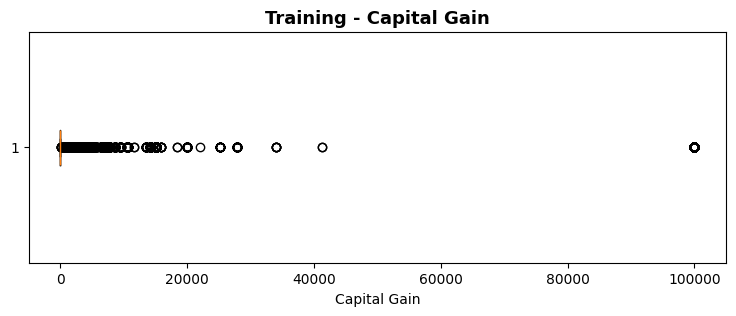

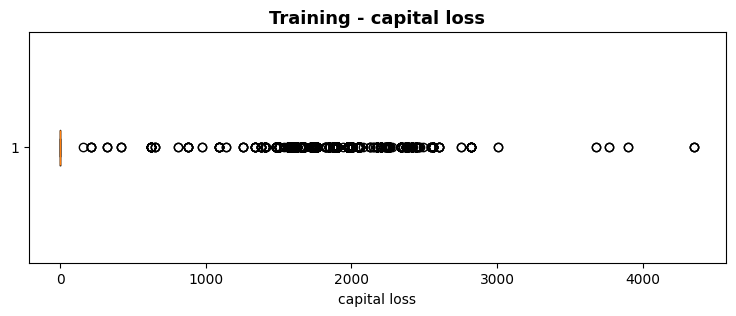

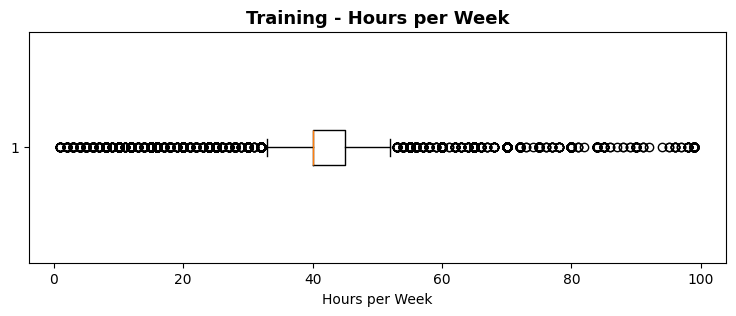

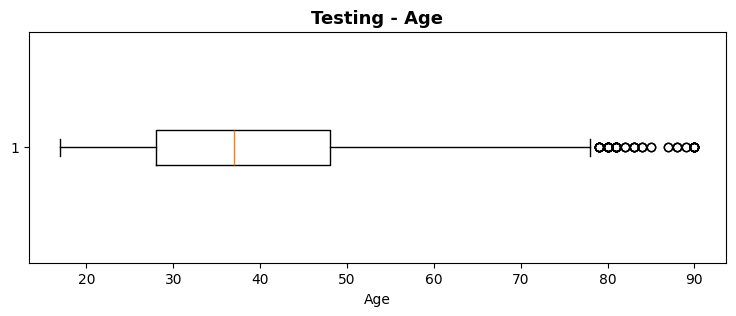

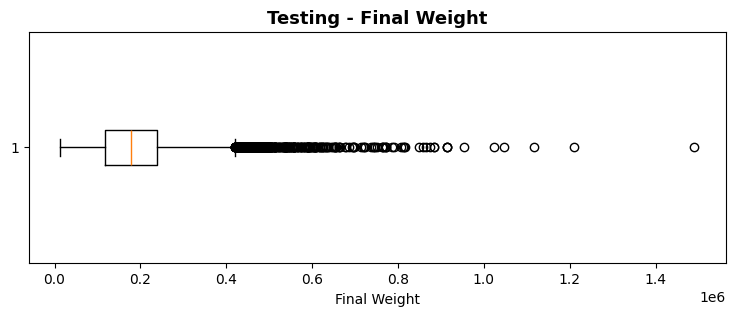

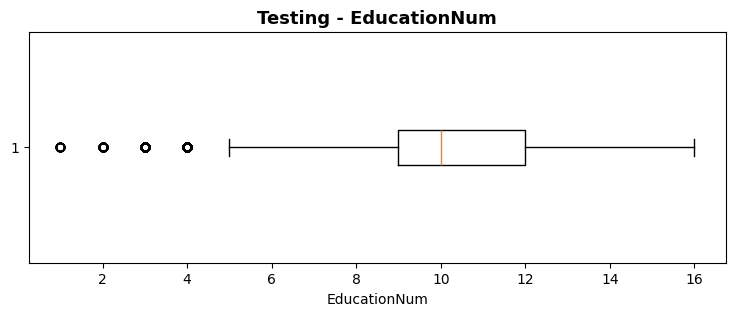

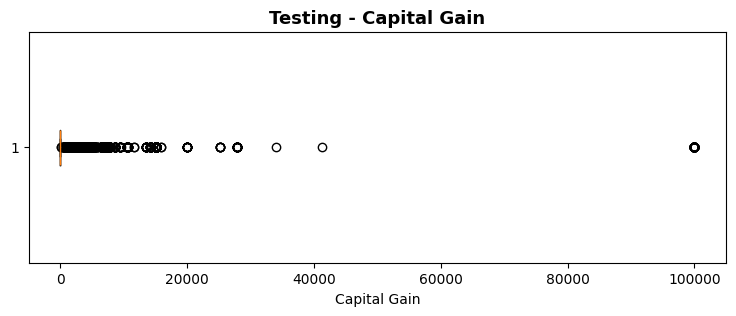

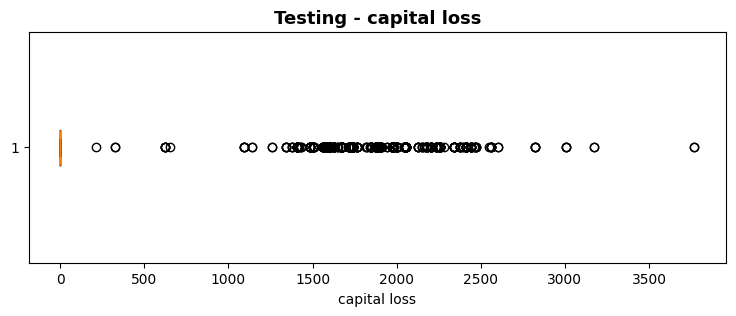

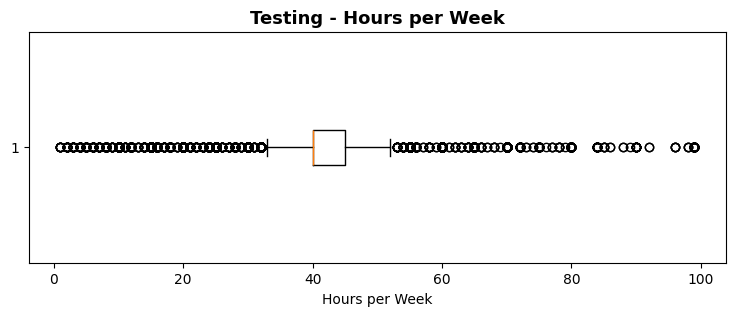

In [ ]:
judul("4. Deteksi Outlier Numerik")

numeric_cols = [
    "Age",
    "Final Weight",
    "EducationNum",
    "Capital Gain",
    "capital loss",
    "Hours per Week"
]

def deteksi_outlier(df):
    hasil = []

    for col in numeric_cols:
        s = pd.to_numeric(df[col], errors="coerce")
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1

        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr

        outlier = (s < batas_bawah) | (s > batas_atas)

        hasil.append({
            "Variabel": col,
            "Minimum": s.min(),
            "Maximum": s.max(),
            "Batas Bawah": batas_bawah,
            "Batas Atas": batas_atas,
            "Jumlah Outlier": outlier.sum(),
            "Persentase (%)": round(outlier.mean() * 100, 2)
        })

    return pd.DataFrame(hasil)

print("OUTLIER DATA TRAINING")
display(deteksi_outlier(train_clean))

print("OUTLIER DATA TESTING")
display(deteksi_outlier(test_clean))

# Boxplot setiap variabel
for nama, df in [("Training", train_clean), ("Testing", test_clean)]:
    for col in numeric_cols:
        plt.figure(figsize=(9, 3))
        plt.boxplot(df[col].dropna(), vert=False)
        plt.title(f"{nama} - {col}", fontsize=13, fontweight="bold")
        plt.xlabel(col)
        plt.show()

## 5.Menganalisis apakah outlier merupakan kesalahan


> Variabel	Pemeriksaan	Interpretasi

Age	Usia negatif atau di atas 110	Perlu ditinjau

Final Weight	Nilai nol atau negatif	Perlu ditinjau

EducationNum	Di luar 1–16	Perlu ditinjau

Capital Gain	Nilai negatif	Tidak wajar

capital loss	Nilai negatif	Tidak wajar

Hours per Week	Kurang dari 1 atau lebih dari 168	Tidak waja



In [ ]:
judul("5. Analisis Nilai Tidak Wajar")

def cek_nilai_tidak_wajar(df):
    aturan = {
        "Age": (df["Age"] < 0) | (df["Age"] > 110),
        "Final Weight": df["Final Weight"] <= 0,
        "EducationNum": ~df["EducationNum"].between(1, 16),
        "Capital Gain": df["Capital Gain"] < 0,
        "capital loss": df["capital loss"] < 0,
        "Hours per Week": ~df["Hours per Week"].between(1, 168)
    }

    hasil = pd.DataFrame({
        "Variabel": list(aturan.keys()),
        "Jumlah Tidak Wajar": [int(x.sum()) for x in aturan.values()]
    })

    return hasil

print("TRAINING")
display(cek_nilai_tidak_wajar(train_clean))

print("TESTING")
display(cek_nilai_tidak_wajar(test_clean))

TRAINING


,Variabel,Jumlah Tidak Wajar
0,Age,0
1,Final Weight,0
2,EducationNum,0
3,Capital Gain,0
4,capital loss,0
5,Hours per Week,0


TESTING


,Variabel,Jumlah Tidak Wajar
0,Age,0
1,Final Weight,0
2,EducationNum,0
3,Capital Gain,0
4,capital loss,0
5,Hours per Week,0


## 6.Menentukan tindakan cleaning


1.   Outlier yang masih valid dipertahankan.
2.   Duplikat identik dipertahankan karena tidak terdapat ID unik responden.
3.   Missing values kategorikal diisi "Unknown".
4.   Missing values numerik, jika ada, diisi median dari data training.




In [ ]:

judul("6. Penanganan Missing Values, Spasi, dan Outlier")

import pandas as pd

# 1. Hapus spasi pada seluruh nilai kategorikal
for df in [train_clean, test_clean]:
    cat_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for col in cat_columns:
        df[col] = df[col].astype("string").str.strip()

        # Ubah tanda ? dan string kosong menjadi NaN
        df[col] = df[col].replace({
            "?": pd.NA,
            "": pd.NA
        })

# 2. Pastikan tidak ada label target yang hilang
assert train_clean["Income"].notna().all()
assert test_clean["Income"].notna().all()

# 3. Periksa nilai numerik tidak wajar
jumlah_invalid = (
    cek_nilai_tidak_wajar(train_clean)["Jumlah Tidak Wajar"].sum()
    + cek_nilai_tidak_wajar(test_clean)["Jumlah Tidak Wajar"].sum()
)

if jumlah_invalid > 0:
    raise ValueError(
        "Ditemukan nilai numerik tidak wajar. "
        "Periksa hasil tahap 5 sebelum melanjutkan."
    )

# 4. Kolom kategorikal, kecuali target
cat_cols = train_clean.select_dtypes(
    include=["object", "string"]
).columns.drop("Income")

# 5. Isi NaN kategorikal dengan Unknown
for col in cat_cols:
    train_clean[col] = train_clean[col].fillna("Unknown")
    test_clean[col] = test_clean[col].fillna("Unknown")

# 6. Isi NaN numerik menggunakan median TRAINING
for col in numeric_cols:
    median_train = train_clean[col].median()

    train_clean[col] = train_clean[col].fillna(median_train)
    test_clean[col] = test_clean[col].fillna(median_train)

# 7. Periksa hasil cleaning
print("Missing values training:", train_clean.isna().sum().sum())
print("Missing values testing :", test_clean.isna().sum().sum())

print("\nUkuran training:", train_clean.shape)
print("Ukuran testing :", test_clean.shape)

# 8. Periksa nilai unik Workclass setelah cleaning
print("\nUnique Values Workclass (Training):")
print(train_clean["Workclass"].unique())

print("\nUnique Values Workclass (Testing):")
print(test_clean["Workclass"].unique())


Missing values training: 0
Missing values testing : 0

Ukuran training: (32561, 15)
Ukuran testing : (16281, 15)

Unique Values Workclass (Training):
<StringArray>
[       'State-gov', 'Self-emp-not-inc',          'Private',
      'Federal-gov',        'Local-gov',          'Unknown',
     'Self-emp-inc',      'Without-pay',     'Never-worked']
Length: 9, dtype: string

Unique Values Workclass (Testing):
<StringArray>
[         'Private',        'Local-gov',          'Unknown',
 'Self-emp-not-inc',      'Federal-gov',        'State-gov',
     'Self-emp-inc',      'Without-pay',     'Never-worked']
Length: 9, dtype: string


## 7.Simpan hasil cleaning

In [ ]:
# Simpan dataset setelah cleaning, sebelum encoding
train_clean.to_csv("adultclean.csv", index=False)
test_clean.to_csv("adult.test.clean.csv", index=False)

# Tampilkan hasil
print("=== TRAINING CLEAN ===")
print("Ukuran:", train_clean.shape)
display(train_clean.head())

print("\n=== TESTING CLEAN ===")
print("Ukuran:", test_clean.shape)
display(test_clean.head())

=== TRAINING CLEAN ===
Ukuran: (32561, 15)


,Age,Workclass,Final Weight,Education,EducationNum,Marital Status,Occupation,Relationship,Race,Gender,Capital Gain,capital loss,Hours per Week,Native Country,Income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



=== TESTING CLEAN ===
Ukuran: (16281, 15)


,Age,Workclass,Final Weight,Education,EducationNum,Marital Status,Occupation,Relationship,Race,Gender,Capital Gain,capital loss,Hours per Week,Native Country,Income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Unknown,103497,Some-college,10,Never-married,Unknown,Own-child,White,Female,0,0,30,United-States,<=50K


# Step 6: Encoding dan Persiapan Klasifikasi


rules that used for  encode
- 6 variabel nominal: One-Hot Encoding.
- 1 variabel biner (Gender): Binary Mapping.
- 1 variabel ordinal (Education): menggunakan EducationNum.
- 1 target (Income): Binary Mapping.
- 5 variabel numerik lainnya: tidak memerlukan encoding.

In [ ]:

judul("5. Encoding dan Persiapan Klasifikasi")

import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# 1. Pisahkan fitur dan target
# Education dihapus karena sudah diwakili EducationNum
X_train = train_clean.drop(columns=["Income", "Education"]).copy()
X_test = test_clean.drop(columns=["Income", "Education"]).copy()

# 2. Encoding target Income (Binary Mapping)
label_map = {
    "<=50K": 0,
    ">50K": 1
}

y_train = train_clean["Income"].str.strip().str.rstrip(".").map(label_map)
y_test = test_clean["Income"].str.strip().str.rstrip(".").map(label_map)

assert y_train.notna().all(), "Ada label training tidak dikenal"
assert y_test.notna().all(), "Ada label testing tidak dikenal"

y_train = y_train.astype(int)
y_test = y_test.astype(int)

# 3. Binary Mapping untuk Gender
gender_map = {
    "Female": 0,
    "Male": 1
}

for df in [X_train, X_test]:
    df["Gender"] = df["Gender"].map(gender_map)

assert X_train["Gender"].notna().all(), "Ada Gender training tidak dikenal"
assert X_test["Gender"].notna().all(), "Ada Gender testing tidak dikenal"

X_train["Gender"] = X_train["Gender"].astype(int)
X_test["Gender"] = X_test["Gender"].astype(int)

# 4. One-Hot Encoding untuk variabel nominal
nominal_cols = [
    "Workclass",
    "Marital Status",
    "Occupation",
    "Relationship",
    "Race",
    "Native Country"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=int
)

# Fit hanya pada training
train_encoded = encoder.fit_transform(
    X_train[nominal_cols]
)

# Testing menggunakan encoder yang sama
test_encoded = encoder.transform(
    X_test[nominal_cols]
)

# 5. Nama kolom One-Hot Encoding
encoded_cols = encoder.get_feature_names_out(nominal_cols)

train_cat = pd.DataFrame(
    train_encoded,
    columns=encoded_cols,
    index=X_train.index
)

test_cat = pd.DataFrame(
    test_encoded,
    columns=encoded_cols,
    index=X_test.index
)

# 6. Ambil fitur selain kategori nominal
X_train_num = X_train.drop(columns=nominal_cols)
X_test_num = X_test.drop(columns=nominal_cols)

# 7. Gabungkan fitur numerik dan hasil encoding
X_train_final = pd.concat(
    [X_train_num, train_cat], axis=1
)

X_test_final = pd.concat(
    [X_test_num, test_cat], axis=1
)

# 8. Validasi akhir
assert X_train_final.columns.equals(X_test_final.columns)
assert X_train_final.isna().sum().sum() == 0
assert X_test_final.isna().sum().sum() == 0

print("Ukuran X_train:", X_train_final.shape)
print("Ukuran X_test :", X_test_final.shape)

print("\nDistribusi Target Training:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nDistribusi Target Testing:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

# 9. Tampilkan contoh hasil encoding
judul("Hasil Encoding Dataset Training")
display(X_train_final.head())

judul("Hasil Encoding Dataset Testing")
display(X_test_final.head())


Ukuran X_train: (32561, 91)
Ukuran X_test : (16281, 91)

Distribusi Target Training:
Income
0    75.92
1    24.08
Name: proportion, dtype: float64

Distribusi Target Testing:
Income
0    76.38
1    23.62
Name: proportion, dtype: float64


,Age,Final Weight,EducationNum,Gender,Capital Gain,capital loss,Hours per Week,Workclass_Federal-gov,Workclass_Local-gov,Workclass_Never-worked,...,Native Country_Puerto-Rico,Native Country_Scotland,Native Country_South,Native Country_Taiwan,Native Country_Thailand,Native Country_Trinadad&Tobago,Native Country_United-States,Native Country_Unknown,Native Country_Vietnam,Native Country_Yugoslavia
0,39,77516,13,1,2174,0,40,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,50,83311,13,1,0,0,13,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,38,215646,9,1,0,0,40,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3,53,234721,7,1,0,0,40,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,28,338409,13,0,0,0,40,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,Age,Final Weight,EducationNum,Gender,Capital Gain,capital loss,Hours per Week,Workclass_Federal-gov,Workclass_Local-gov,Workclass_Never-worked,...,Native Country_Puerto-Rico,Native Country_Scotland,Native Country_South,Native Country_Taiwan,Native Country_Thailand,Native Country_Trinadad&Tobago,Native Country_United-States,Native Country_Unknown,Native Country_Vietnam,Native Country_Yugoslavia
0,25,226802,7,1,0,0,40,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,38,89814,9,1,0,0,50,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,28,336951,12,1,0,0,40,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,44,160323,10,1,7688,0,40,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,18,103497,10,0,0,0,30,0,0,0,...,0,0,0,0,0,0,1,0,0,0


# Step 7: Balancing dengan SMOTE setelah Encoding

SMOTE hanya pada training. Testing asli tidak diubah. **Perhatian:** SMOTE standar pada fitur One-Hot dapat menghasilkan angka pecahan pada kategori; hasil ini adalah baseline numerik, bukan representasi kategori murni. Untuk validasi silang, oversampling harus dilakukan di dalam fold training.


In [ ]:
judul("7. Balancing Target Income dengan SMOTE (setelah Encoding)")

from imblearn.over_sampling import SMOTE

# X_train_final dan y_train berasal dari tahap Encoding (Step 5).
# Testing X_test_final / y_test TIDAK dilakukan SMOTE.
assert X_train_final.columns.equals(X_test_final.columns)
assert X_train_final.notna().all().all()
assert X_test_final.notna().all().all()
assert y_train.isin([0, 1]).all()

smote = SMOTE(sampling_strategy="auto", random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train_final, y_train)

# Pertahankan nama dan urutan kolom
X_train_smote = pd.DataFrame(X_train_smote, columns=X_train_final.columns)
y_train_smote = pd.Series(y_train_smote, name="Income").astype(int)

print("Sebelum SMOTE:")
print(y_train.value_counts().sort_index())
print("\nSesudah SMOTE:")
print(y_train_smote.value_counts().sort_index())
print("\nTraining sebelum:", X_train_final.shape)
print("Training sesudah:", X_train_smote.shape)
print("Testing tetap:", X_test_final.shape)


Sebelum SMOTE:
Income
0    24720
1     7841
Name: count, dtype: int64

Sesudah SMOTE:
Income
0    24720
1    24720
Name: count, dtype: int64

Training sebelum: (32561, 91)
Training sesudah: (49440, 91)
Testing tetap: (16281, 91)


# Step 8: Visualisasi distribusi Income sebelum dan sesudah SMOTE


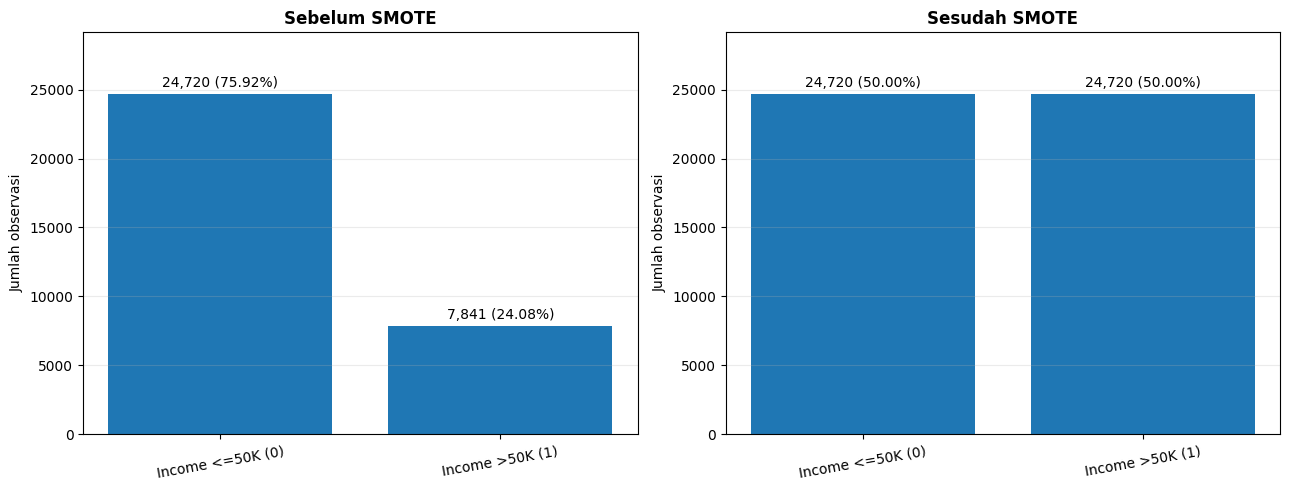

Ringkasan distribusi:


,Sebelum SMOTE,Sesudah SMOTE
Income,,
0,24720,24720
1,7841,24720


In [ ]:
judul("8. Distribusi Income Sebelum dan Sesudah SMOTE")

before = y_train.value_counts().reindex([0, 1], fill_value=0)
after = y_train_smote.value_counts().reindex([0, 1], fill_value=0)
labels = ["Income <=50K (0)", "Income >50K (1)"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
max_count = max(before.max(), after.max())
for ax, counts, title in [
    (axes[0], before, "Sebelum SMOTE"),
    (axes[1], after, "Sesudah SMOTE")
]:
    bars = ax.bar(labels, counts.values)
    for bar, total_kelas in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max_count*0.02,
                f"{total_kelas:,} ({total_kelas/counts.sum()*100:.2f}%)",
                ha="center", fontsize=10)
    ax.set_ylim(0, max_count*1.18)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Jumlah observasi")
    ax.tick_params(axis="x", labelrotation=10)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Ringkasan distribusi:")
display(pd.DataFrame({"Sebelum SMOTE": before, "Sesudah SMOTE": after}))


# Step 9: Simpan dataset bersih, encoded, dan hasil SMOTE

Tiga file terpisah: training asli encoded, training setelah SMOTE, dan testing asli encoded.


In [ ]:
judul("9. Dataset Siap untuk Pemodelan")

# Training asli sesudah encoding (Before SMOTE)
adultclean = X_train_final.reset_index(drop=True).copy()
adultclean["Income"] = y_train.to_numpy()

# Training sesudah SMOTE (After SMOTE)
adultclean_smote = X_train_smote.reset_index(drop=True).copy()
adultclean_smote["Income"] = y_train_smote.to_numpy()

# Testing: tidak di-SMOTE
adult_testclean = X_test_final.reset_index(drop=True).copy()
adult_testclean["Income"] = y_test.to_numpy()

assert adultclean.columns.equals(adult_testclean.columns)
assert adultclean_smote.columns.equals(adult_testclean.columns)
for nama, df in [
    ("Training asli", adultclean),
    ("Training SMOTE", adultclean_smote),
    ("Testing", adult_testclean)
]:
    assert not df.isna().any().any(), f"Missing value pada {nama}"
    assert df["Income"].isin([0, 1]).all(), f"Income tidak valid pada {nama}"
    assert df.drop(columns="Income").select_dtypes(exclude="number").empty, f"Fitur non-numerik: {nama}"

adultclean.to_csv("adultclean_encode.csv", index=False)
adultclean_smote.to_csv("adultclean_smote_encode.csv", index=False)
adult_testclean.to_csv("adult.test.clean_encode.csv", index=False)

for nama, df in [
    ("Training asli: adultclean_encode.csv", adultclean),
    ("Training SMOTE: adultclean_smote_encode.csv", adultclean_smote),
    ("Testing asli: adult.test.clean_encode.csv", adult_testclean)
]:
    print("\n===", nama, "===")
    print("Ukuran:", df.shape)
    print("Distribusi Income:", df["Income"].value_counts().sort_index().to_dict())
    display(df.head())

print("\nKetiga file tersedia di panel Files Colab (/content/).")



=== Training asli: adultclean_encode.csv ===
Ukuran: (32561, 92)
Distribusi Income: {0: 24720, 1: 7841}


,Age,Final Weight,EducationNum,Gender,Capital Gain,capital loss,Hours per Week,Workclass_Federal-gov,Workclass_Local-gov,Workclass_Never-worked,...,Native Country_Scotland,Native Country_South,Native Country_Taiwan,Native Country_Thailand,Native Country_Trinadad&Tobago,Native Country_United-States,Native Country_Unknown,Native Country_Vietnam,Native Country_Yugoslavia,Income
0,39,77516,13,1,2174,0,40,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,50,83311,13,1,0,0,13,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,38,215646,9,1,0,0,40,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,53,234721,7,1,0,0,40,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,28,338409,13,0,0,0,40,0,0,0,...,0,0,0,0,0,0,0,0,0,0



=== Training SMOTE: adultclean_smote_encode.csv ===
Ukuran: (49440, 92)
Distribusi Income: {0: 24720, 1: 24720}


,Age,Final Weight,EducationNum,Gender,Capital Gain,capital loss,Hours per Week,Workclass_Federal-gov,Workclass_Local-gov,Workclass_Never-worked,...,Native Country_Scotland,Native Country_South,Native Country_Taiwan,Native Country_Thailand,Native Country_Trinadad&Tobago,Native Country_United-States,Native Country_Unknown,Native Country_Vietnam,Native Country_Yugoslavia,Income
0,39,77516,13,1,2174,0,40,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,50,83311,13,1,0,0,13,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,38,215646,9,1,0,0,40,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,53,234721,7,1,0,0,40,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,28,338409,13,0,0,0,40,0,0,0,...,0,0,0,0,0,0,0,0,0,0



=== Testing asli: adult.test.clean_encode.csv ===
Ukuran: (16281, 92)
Distribusi Income: {0: 12435, 1: 3846}


,Age,Final Weight,EducationNum,Gender,Capital Gain,capital loss,Hours per Week,Workclass_Federal-gov,Workclass_Local-gov,Workclass_Never-worked,...,Native Country_Scotland,Native Country_South,Native Country_Taiwan,Native Country_Thailand,Native Country_Trinadad&Tobago,Native Country_United-States,Native Country_Unknown,Native Country_Vietnam,Native Country_Yugoslavia,Income
0,25,226802,7,1,0,0,40,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,38,89814,9,1,0,0,50,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,28,336951,12,1,0,0,40,0,1,0,...,0,0,0,0,0,1,0,0,0,1
3,44,160323,10,1,7688,0,40,0,0,0,...,0,0,0,0,0,1,0,0,0,1
4,18,103497,10,0,0,0,30,0,0,0,...,0,0,0,0,0,1,0,0,0,0



Ketiga file tersedia di panel Files Colab (/content/).


# Step 10: Persiapan training dan testing

Kelima model diuji dengan training sebelum dan sesudah SMOTE. Testing tetap data asli dan sama pada seluruh pengujian. **SMOTE standar pada kolom one-hot adalah baseline eksperimen; kolom dummy sintetis dapat pecahan.**

In [ ]:
 # persian library, dataset, dan fungsi untuk  training dan testing
%pip -q install xgboost

import pandas as pd
import numpy as np
from IPython.display import display

# dataset untuk training (sdh cleaning, encode, dan smote)
train_before = pd.read_csv("adultclean_encode.csv")
train_after = pd.read_csv("adultclean_smote_encode.csv")
# dataset untuk testing  (sdh cleaning dan encode tapi masih data asli tdk di smote)
test = pd.read_csv("adult.test.clean_encode.csv")

X_before = train_before.drop(columns="Income")
y_before = train_before["Income"].astype(int)
X_after = train_after.drop(columns="Income")
y_after = train_after["Income"].astype(int)
X_test = test.drop(columns="Income")
y_test = test["Income"].astype(int)

assert X_before.columns.equals(X_after.columns) and X_before.columns.equals(X_test.columns)
for name, X, y in [("Before SMOTE", X_before, y_before),
                   ("After SMOTE", X_after, y_after), ("Testing", X_test, y_test)]:
    assert X.select_dtypes(exclude="number").empty, f"Fitur bukan angka: {name}"
    assert not X.isna().any().any(), f"Missing values: {name}"
    assert y.isin([0, 1]).all(), f"Target tidak sesuai: {name}"
    print(name, X.shape, y.value_counts().sort_index().to_dict())


Before SMOTE (32561, 91) {0: 24720, 1: 7841}
After SMOTE (49440, 91) {0: 24720, 1: 24720}
Testing (16281, 91) {0: 12435, 1: 3846}


# Step 11: Definisi lima model

Logistic Regression memakai standardisasi fitur numerik dengan scaler yang di-**fit** hanya pada training masing-masing eksperimen. Model lain tidak membutuhkan standardisasi. Parameter berikut adalah konfigurasi awal, bukan hasil tuning.

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

numeric_features = ["Age", "Final Weight", "EducationNum", "Capital Gain", "capital loss", "Hours per Week"]
assert set(numeric_features).issubset(X_before.columns)

models = {
    "Logistic Regression": Pipeline([
        ("scale", ColumnTransformer(
            [("num", StandardScaler(), numeric_features)],
            remainder="passthrough")),
        ("model", LogisticRegression(max_iter=3000, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8,
                              tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=150, learning_rate=0.5, random_state=42)
}
print("Model:", list(models))


Model: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'AdaBoost']


# Step 12: Training, testing, dan evaluasi 10 eksperimen

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, roc_auc_score, confusion_matrix,
                             classification_report)

results = []
predictions = {}
trained_models = {}

for model_name, base_model in models.items():
    for condition, X_fit, y_fit in [
        ("Before SMOTE", X_before, y_before),
        ("After SMOTE", X_after, y_after)
    ]:
        model = clone(base_model)
        model.fit(X_fit, y_fit)
        pred = model.predict(X_test)
        prob = model.predict_proba(X_test)[:, 1]

        results.append({
            "Model": model_name,
            "Kondisi": condition,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1 Score": f1_score(y_test, pred, zero_division=0),
            "F2 Score": fbeta_score(y_test, pred, beta=2, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, prob),
        })
        predictions[(model_name, condition)] = pred
        trained_models[(model_name, condition)] = model
        print(f"Selesai: {model_name} | {condition}")

hasil_df = pd.DataFrame(results)
display(hasil_df.round(4))


Selesai: Logistic Regression | Before SMOTE
Selesai: Logistic Regression | After SMOTE
Selesai: Decision Tree | Before SMOTE
Selesai: Decision Tree | After SMOTE
Selesai: Random Forest | Before SMOTE
Selesai: Random Forest | After SMOTE
Selesai: XGBoost | Before SMOTE
Selesai: XGBoost | After SMOTE
Selesai: AdaBoost | Before SMOTE
Selesai: AdaBoost | After SMOTE


,Model,Kondisi,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC AUC
0,Logistic Regression,Before SMOTE,0.8528,0.7286,0.6004,0.6583,0.6223,0.9053
1,Logistic Regression,After SMOTE,0.8519,0.7120,0.6261,0.6663,0.6416,0.9057
2,Decision Tree,Before SMOTE,0.8611,0.7648,0.5952,0.6694,0.6228,0.9041
3,Decision Tree,After SMOTE,0.8237,0.6174,0.6674,0.6414,0.6568,0.8776
4,Random Forest,Before SMOTE,0.8662,0.7757,0.6097,0.6828,0.6370,0.9176
5,Random Forest,After SMOTE,0.8569,0.7020,0.6854,0.6936,0.6886,0.9129
6,XGBoost,Before SMOTE,0.8756,0.7878,0.6477,0.7109,0.6716,0.9270
7,XGBoost,After SMOTE,0.8567,0.6890,0.7171,0.7028,0.7113,0.9161
8,AdaBoost,Before SMOTE,0.8571,0.7782,0.5528,0.6464,0.5868,0.9104
9,AdaBoost,After SMOTE,0.8134,0.5747,0.8079,0.6716,0.7472,0.8992


# Step 13: Matriks perbandingan metrik dan selisih SMOTE

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "F2 Score", "ROC AUC"]
comparison = hasil_df.pivot(index="Model", columns="Kondisi", values=metrics)
comparison = comparison.reindex(columns=pd.MultiIndex.from_product(
    [metrics, ["Before SMOTE", "After SMOTE"]]))
display(comparison.round(4))

selisih = pd.DataFrame({m: comparison[(m, "After SMOTE")] - comparison[(m, "Before SMOTE")]
                        for m in metrics})
print("Selisih After - Before (positif = naik):")
display(selisih.round(4))


Accuracy                Precision              \
                    Before SMOTE After SMOTE Before SMOTE After SMOTE   
Model                                                                   
AdaBoost                  0.8571      0.8134       0.7782      0.5747   
Decision Tree             0.8611      0.8237       0.7648      0.6174   
Logistic Regression       0.8528      0.8519       0.7286      0.7120   
Random Forest             0.8662      0.8569       0.7757      0.7020   
XGBoost                   0.8756      0.8567       0.7878      0.6890   

                          Recall                 F1 Score              \
                    Before SMOTE After SMOTE Before SMOTE After SMOTE   
Model                                                                   
AdaBoost                  0.5528      0.8079       0.6464      0.6716   
Decision Tree             0.5952      0.6674       0.6694      0.6414   
Logistic Regression       0.6004      0.6261       0.6583      0.6663   
Random Forest             0.6097      0.6854       0.6828      0.6936   
XGBoost                   0.6477      0.7171       0.7109      0.7028   

                        F2 Score                  ROC AUC              
                    Before SMOTE After SMOTE Before SMOTE After SMOTE  
Model                                                                  
AdaBoost                  0.5868      0.7472       0.9104      0.8992  
Decision Tree             0.6228      0.6568       0.9041      0.8776  
Logistic Regression       0.6223      0.6416       0.9053      0.9057  
Random Forest             0.6370      0.6886       0.9176      0.9129  
XGBoost                   0.6716      0.7113       0.9270      0.9161

Selisih After - Before (positif = naik):


,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC AUC
Model,,,,,,
AdaBoost,-0.0437,-0.2035,0.2551,0.0252,0.1605,-0.0112
Decision Tree,-0.0374,-0.1474,0.0723,-0.0280,0.0340,-0.0266
Logistic Regression,-0.0009,-0.0166,0.0257,0.0080,0.0193,0.0005
Random Forest,-0.0092,-0.0737,0.0757,0.0108,0.0517,-0.0047
XGBoost,-0.0189,-0.0988,0.0694,-0.0081,0.0397,-0.0109


# Step 14: Grafik perbandingan keenam metrik

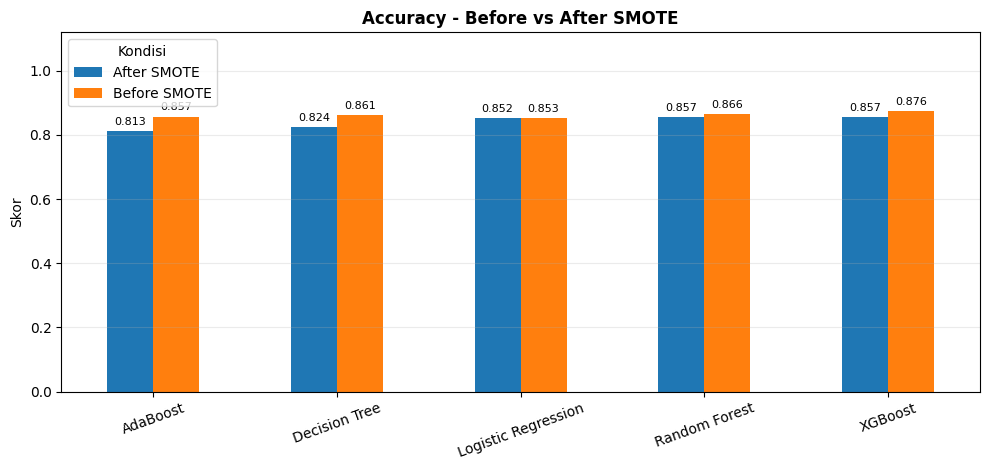

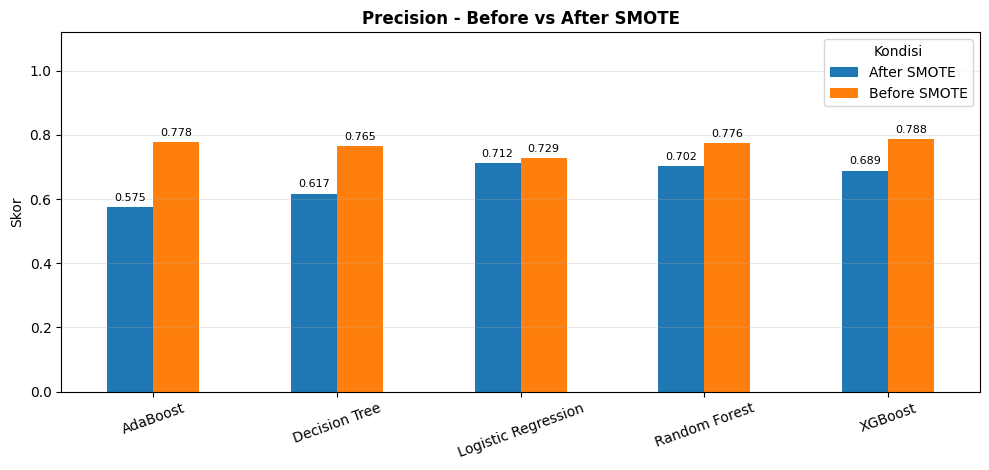

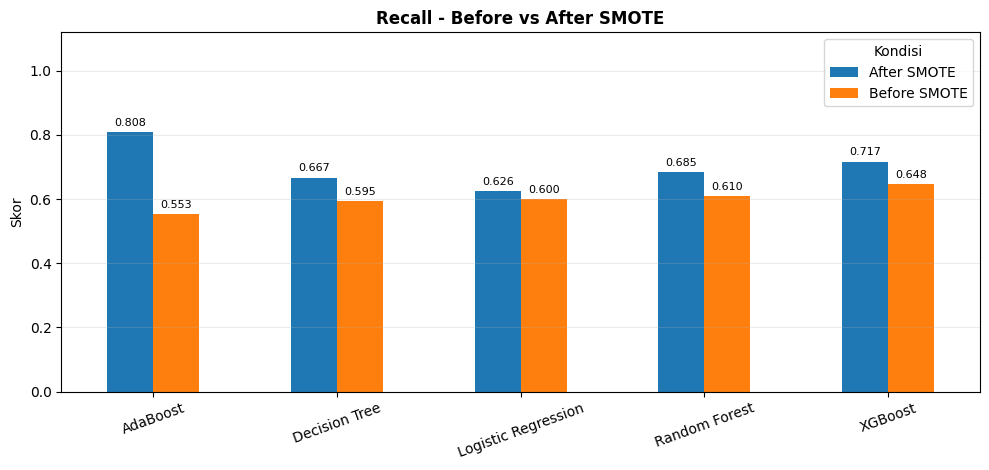

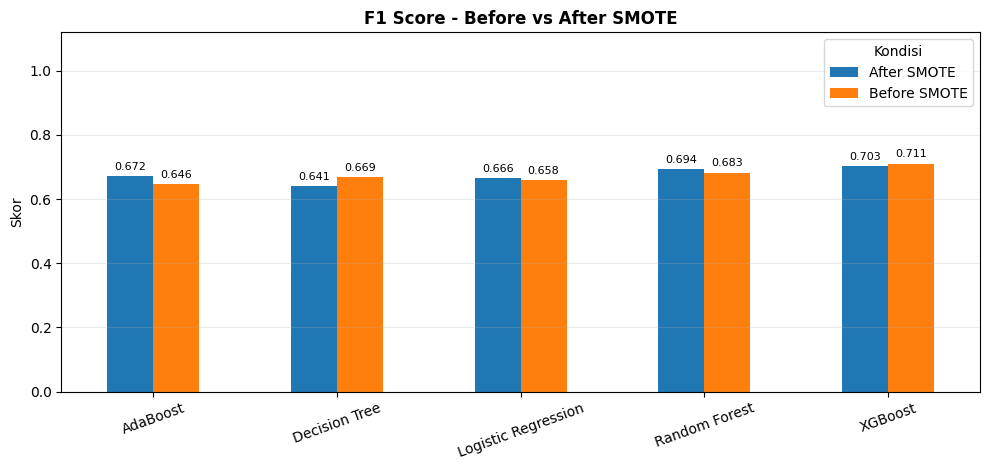

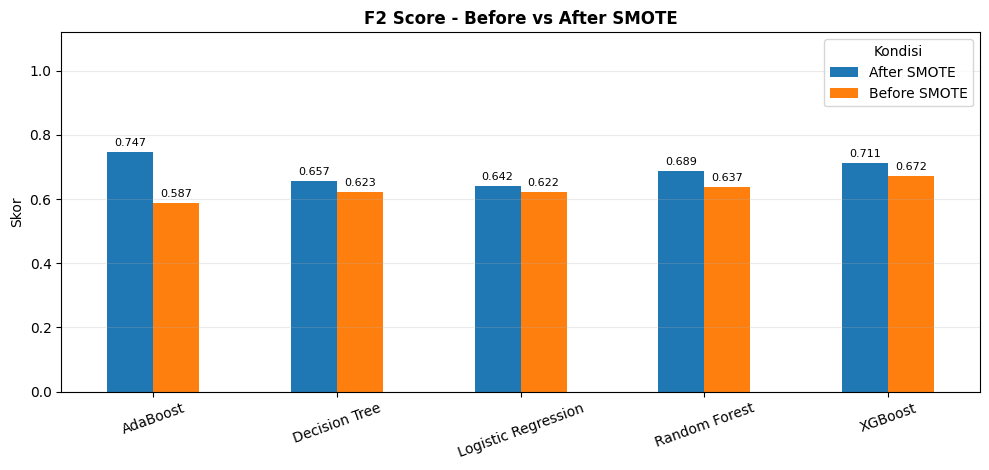

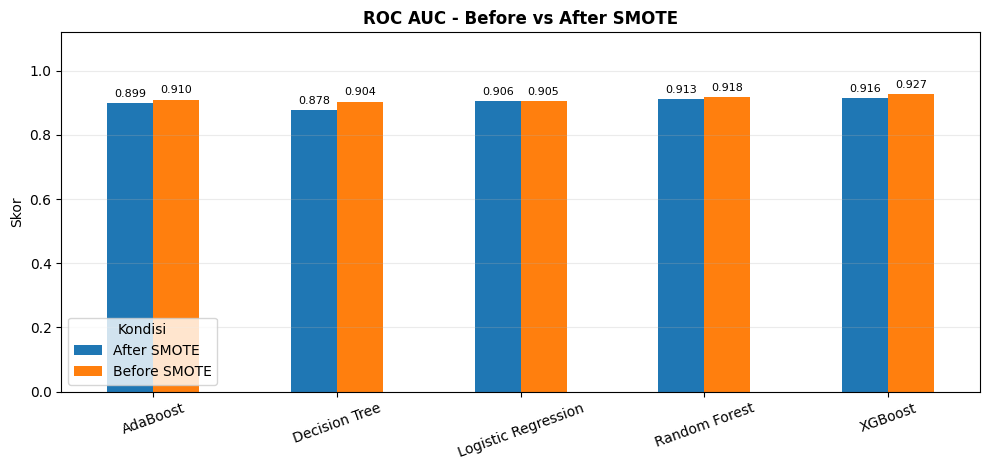

In [ ]:
import matplotlib.pyplot as plt

for metric in metrics:
    plot_df = hasil_df.pivot(index="Model", columns="Kondisi", values=metric)
    ax = plot_df.plot.bar(figsize=(10, 4.8), rot=20)
    ax.set_title(f"{metric} - Before vs After SMOTE", fontweight="bold")
    ax.set_ylim(0, 1.12)
    ax.set_xlabel("")
    ax.set_ylabel("Skor")
    ax.grid(axis="y", alpha=0.25)
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    plt.tight_layout()
    plt.show()


## Visualisasi ROC AUC

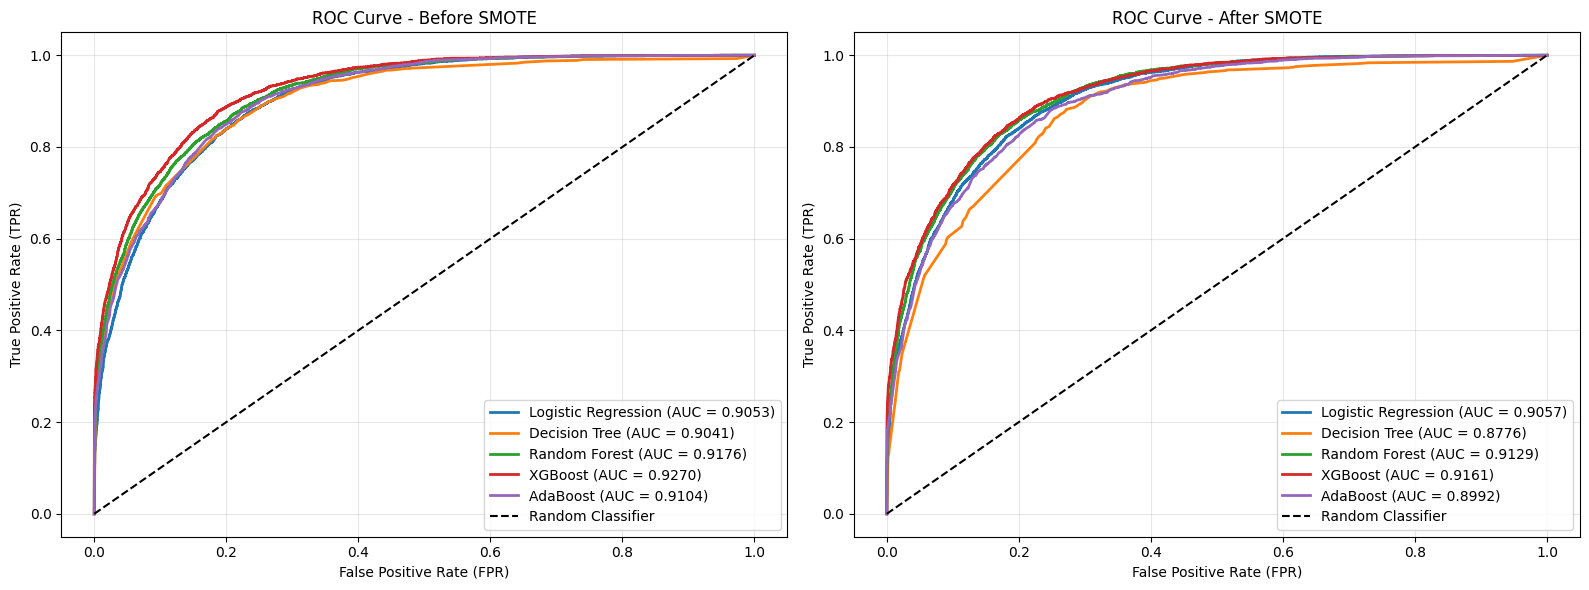

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

conditions = ["Before SMOTE", "After SMOTE"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, condition in zip(axes, conditions):

    for model_name in models.keys():

        # Mengambil model yang sudah dilatih
        model = trained_models[(model_name, condition)]

        # Menghitung probabilitas kelas Income >50K
        y_prob = model.predict_proba(X_test)[:, 1]

        # Menghitung ROC Curve dan AUC
        fpr, tpr, thresholds = roc_curve(y_test, y_prob)
        auc_score = roc_auc_score(y_test, y_prob)

        # Menampilkan ROC Curve
        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{model_name} (AUC = {auc_score:.4f})"
        )

    ax.plot([0, 1], [0, 1], "k--", label="Random Classifier")

    ax.set_title(f"ROC Curve - {condition}")
    ax.set_xlabel("False Positive Rate (FPR)")
    ax.set_ylabel("True Positive Rate (TPR)")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## tabel perbandingan ROC sebelum dan sesudah SMOTE

In [ ]:
# Membuat tabel perbandingan ROC AUC
auc_comparison = hasil_df.pivot(
    index="Model",
    columns="Kondisi",
    values="ROC AUC"
)

auc_comparison["Difference"] = (
    auc_comparison["After SMOTE"] -
    auc_comparison["Before SMOTE"]
)

# Urutkan dari AUC tertinggi setelah SMOTE
auc_comparison = auc_comparison.sort_values(
    by="After SMOTE",
    ascending=False
)

display(auc_comparison.round(4))

Kondisi,After SMOTE,Before SMOTE,Difference
Model,,,
XGBoost,0.9161,0.9270,-0.0109
Random Forest,0.9129,0.9176,-0.0047
Logistic Regression,0.9057,0.9053,0.0005
AdaBoost,0.8992,0.9104,-0.0112
Decision Tree,0.8776,0.9041,-0.0266


# Step 15: Confusion matrix sebelum dan sesudah SMOTE

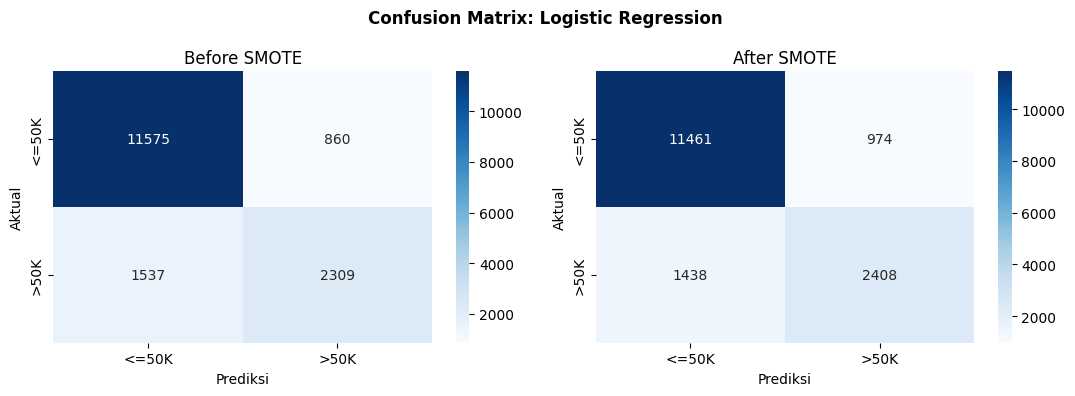

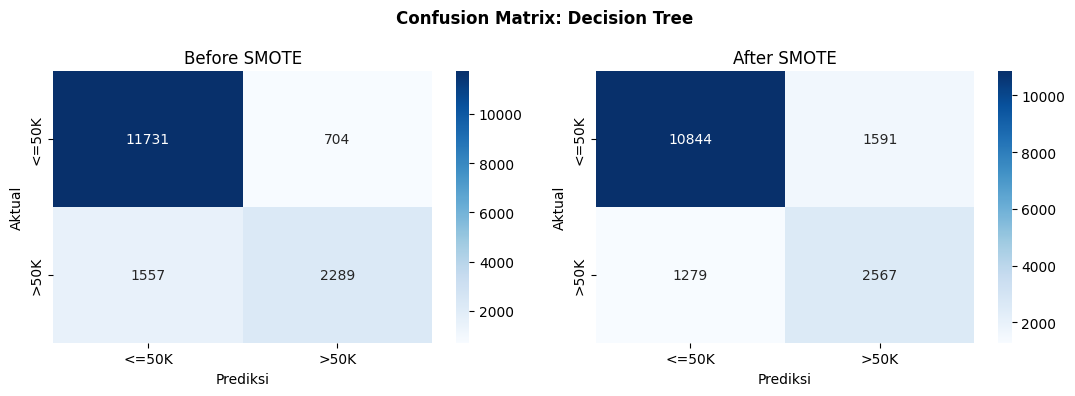

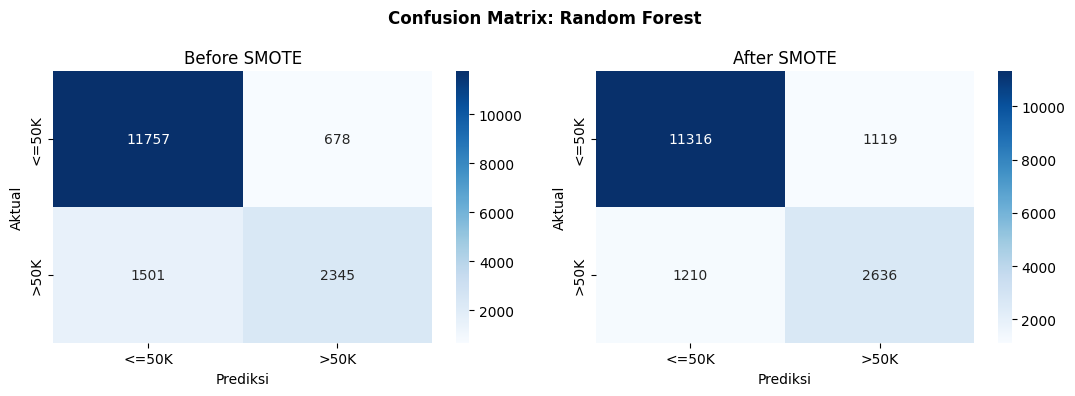

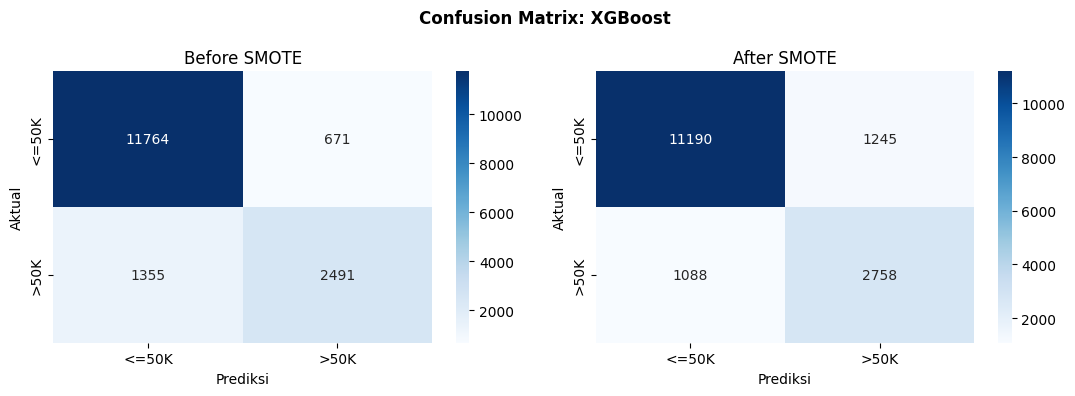

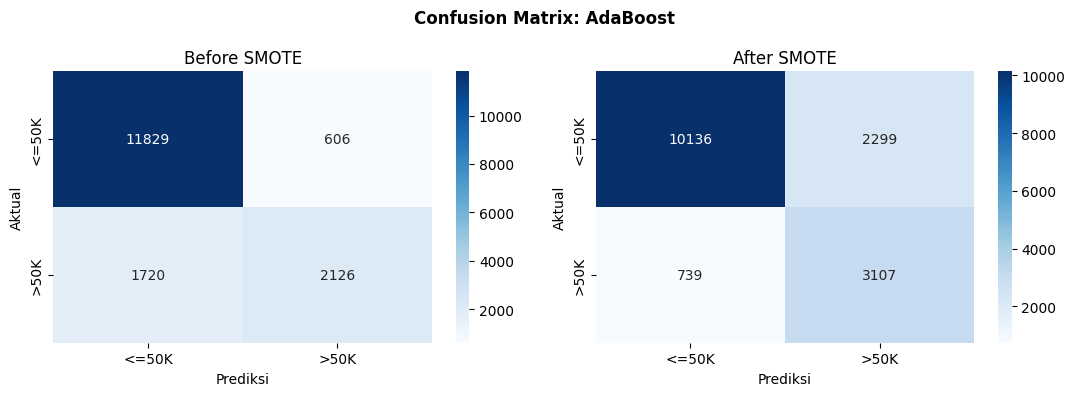

In [ ]:
import seaborn as sns

for model_name in models:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, condition in zip(axes, ["Before SMOTE", "After SMOTE"]):
        cm = confusion_matrix(y_test, predictions[(model_name, condition)], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                    xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
        ax.set_title(condition)
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
    fig.suptitle(f"Confusion Matrix: {model_name}", fontweight="bold")
    plt.tight_layout()
    plt.show()


# Step 16: Classification report dan ekspor hasil

Jangan menentukan model final dengan mengoptimalkan hasil *testing* berulang kali. Untuk pemilihan model, gunakan validasi pada training dan terapkan SMOTE di dalam tiap fold.

In [ ]:
for model_name in models:
    for condition in ["Before SMOTE", "After SMOTE"]:
        print(f"\n=== {model_name} | {condition} ===")
        print(classification_report(y_test, predictions[(model_name, condition)],
                                    labels=[0, 1], target_names=["<=50K", ">50K"],
                                    digits=4, zero_division=0))

hasil_df.to_csv("Evaluasi_5_Model_Adult.csv", index=False)
comparison.to_csv("Perbandingan_5_Model_Before_After_SMOTE.csv")
selisih.to_csv("Selisih_Performa_5_Model_SMOTE.csv")
print("CSV berhasil disimpan di sesi Colab.")



=== Logistic Regression | Before SMOTE ===
              precision    recall  f1-score   support

       <=50K     0.8828    0.9308    0.9062     12435
        >50K     0.7286    0.6004    0.6583      3846

    accuracy                         0.8528     16281
   macro avg     0.8057    0.7656    0.7822     16281
weighted avg     0.8464    0.8528    0.8476     16281


=== Logistic Regression | After SMOTE ===
              precision    recall  f1-score   support

       <=50K     0.8885    0.9217    0.9048     12435
        >50K     0.7120    0.6261    0.6663      3846

    accuracy                         0.8519     16281
   macro avg     0.8003    0.7739    0.7855     16281
weighted avg     0.8468    0.8519    0.8485     16281


=== Decision Tree | Before SMOTE ===
              precision    recall  f1-score   support

       <=50K     0.8828    0.9434    0.9121     12435
        >50K     0.7648    0.5952    0.6694      3846

    accuracy                         0.8611     16281
   

# Step 17 Model Deployment

## MODEL TERPILIH : XGBoost utk deployment

## Tahapan Deployment

ahapan deployment
Tahap	       Kegiatan	                             Tempat

### 1	          Simpan model XGBoost dan preprocessing	Google Colab

### 2	          Download file model	                    Google Colab

### 3            	Buat aplikasi app.py	                 Google Colab

### 4          	Buat requirements.txt	                   Google Colab

### 5	          Upload file project	                      GitHub

### 6	          Deploy aplikasi	                         Streamlit Cloud

### 7	            Uji prediksi melalui website	           Browser

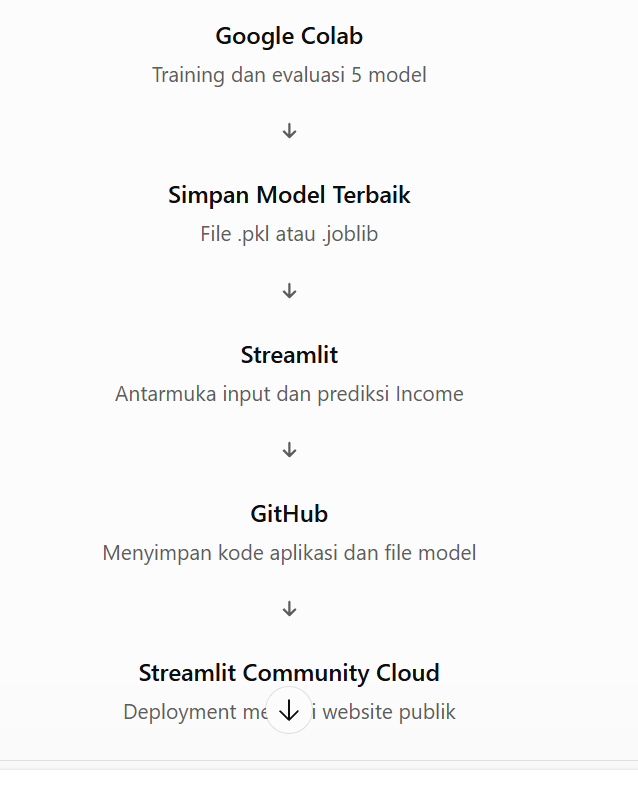

In [ ]:
trained_models[("XGBoost", "After SMOTE")]

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

### Tahap 1.Menyimpan Model XBoost

In [ ]:
import joblib

# Pilih salah satu sesuai hasil evaluasi
condition = "After SMOTE"  # atau "Before SMOTE"

# Ambil model XGBoost yang sudah dilatih
model_xgb = trained_models[("XGBoost", condition)]

# Simpan model
joblib.dump(model_xgb, "model_income_xgboost.pkl")

print("Model XGBoost berhasil disimpan!")

Model XGBoost berhasil disimpan!


### Langkah 2. Menyimpan preprocessing

In [ ]:
import joblib

numeric_cols = [
    "Age",
    "Final Weight",
    "EducationNum",
    "Capital Gain",
    "capital loss",
    "Hours per Week"
]

preprocessing = {
    "encoder": encoder,
    "nominal_cols": nominal_cols,
    "feature_columns": list(X_after.columns),
    "numeric_cols": numeric_cols,
    "numeric_medians": {
        col: float(train_clean[col].median())
        for col in numeric_cols
    }
}

joblib.dump(
    preprocessing,
    "preprocessing_income.pkl"
)

print("Preprocessing berhasil disimpan.")

Preprocessing berhasil disimpan.


### Langkah 3. Download file model dan preprocessing

In [ ]:
from google.colab import files

files.download("model_income_xgboost.pkl")
files.download("preprocessing_income.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Langkah 4. Membuat aplikasi Streamlit

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Income Prediction",
    page_icon="📊",
    layout="centered"
)

@st.cache_resource
def load_files():
    model = joblib.load("model_income_xgboost.pkl")
    prep = joblib.load("preprocessing_income.pkl")
    return model, prep

model, prep = load_files()

st.title("Income Prediction using XGBoost")
st.write(
    "Predict whether annual income is <=50K or >50K "
    "using a machine learning model trained with SMOTE."
)

# Kolom numerik
numeric_values = {}

st.subheader("Personal Information")

for col in prep["numeric_cols"]:
    default = prep["numeric_medians"][col]

    numeric_values[col] = st.number_input(
        col,
        value=float(default),
        step=1.0,
    )

# Gender
gender = st.selectbox(
    "Gender",
    ["Female", "Male"]
)

# Kolom kategorikal
st.subheader("Other Information")

categorical_values = {}

for col, categories in zip(
    prep["nominal_cols"],
    prep["encoder"].categories_
):
    categorical_values[col] = st.selectbox(
        col,
        options=list(categories)
    )

if st.button("Predict Income", type="primary"):

    # Input numerik
    input_data = numeric_values.copy()

    # Encoding gender
    input_data["Gender"] = {
        "Female": 0,
        "Male": 1
    }[gender]

    # DataFrame kategori
    cat_df = pd.DataFrame([categorical_values])

    # Gunakan encoder saat training
    encoded = prep["encoder"].transform(
        cat_df[prep["nominal_cols"]]
    )

    encoded_df = pd.DataFrame(
        encoded,
        columns=prep["encoder"].get_feature_names_out(
            prep["nominal_cols"]
        )
    )

    # Gabungkan fitur
    input_df = pd.concat(
        [pd.DataFrame([input_data]), encoded_df],
        axis=1
    )

    # Samakan urutan fitur dengan training
    input_df = input_df.reindex(
        columns=prep["feature_columns"],
        fill_value=0
    )

    # Prediksi
    prediction = int(model.predict(input_df)[0])
    probability = model.predict_proba(input_df)[0, 1]

    st.subheader("Prediction Result")

    if prediction == 1:
        st.success("Predicted Income: >50K")
    else:
        st.info("Predicted Income: <=50K")

    st.metric(
        "Estimated Probability of Income >50K",
        f"{probability * 100:.2f}%"
    )

    st.caption(
        "This is a statistical prediction, "
        "not a verified income or a decision recommendation."
    )

Writing app.py


### Langkah 5. Membuat requirements.txt

In [ ]:
import importlib.metadata as metadata

packages = {
    "streamlit": None,
    "pandas": "pandas",
    "numpy": "numpy",
    "scikit-learn": "scikit-learn",
    "xgboost": "xgboost",
    "joblib": "joblib"
}

with open("requirements.txt", "w") as f:
    for package, installed_name in packages.items():
        if installed_name:
            version = metadata.version(installed_name)
            f.write(f"{package}=={version}\n")
        else:
            f.write("streamlit\n")

print(open("requirements.txt").read())

streamlit
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1
joblib==1.6.0



In [ ]:
# download kedua file  app.py dan requirements.txt
from google.colab import files

files.download("app.py")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Langkah 6. Upload ke GitHub

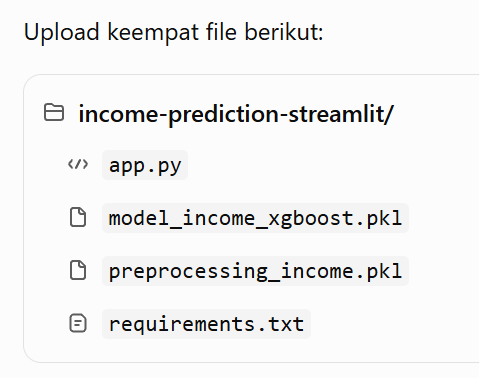

# THANKS